**Programme Title:** HDIP Data Analytics

**Module Title(s):** Machine Learning for Business

**Assignment Title:** CA1

**Lecturer(s):** Dr. Muhammad Iqbal

**Student name:** Battsengel Gantsooj

**Student ID:** 2026124

**Submission date:** 30/10/2026


## Importing variables

In [1]:
import pandas as pd
import numpy as np

print("Pandas:", pd.__version__)
print("NumPy:", np.__version__)

Pandas: 2.2.3
NumPy: 2.1.3


In [2]:
import sys

print(sys.executable)

/usr/bin/python3


In [3]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


## Data Loading

Combining all 6 months of the raw .csv data that's avaible in a sinle .csv file


January = pd.read_csv("/content/drive/MyDrive/Raw Dataset/202101-divvy-tripdata.csv")

February = pd.read_csv("/content/drive/MyDrive/Raw Dataset/202102-divvy-tripdata.csv")

March = pd.read_csv("/content/drive/MyDrive/Raw Dataset/202103-divvy-tripdata.csv")

April = pd.read_csv("/content/drive/MyDrive/Raw Dataset/202104-divvy-tripdata.csv")

May = pd.read_csv("/content/drive/MyDrive/Raw Dataset/202105-divvy-tripdata.csv")

June = pd.read_csv("/content/drive/MyDrive/Raw Dataset/202106-divvy-tripdata.csv")

In [ ]:
January = pd.read_csv("/Raw Dataset/202101-divvy-tripdata.csv")
February = pd.read_csv("/Raw Dataset/202102-divvy-tripdata.csv")
March = pd.read_csv("/Raw Dataset/202103-divvy-tripdata.csv")
April = pd.read_csv("/Raw Dataset/202104-divvy-tripdata.csv")
May = pd.read_csv("/Raw Dataset/202105-divvy-tripdata.csv")
June = pd.read_csv("/Raw Dataset/202106-divvy-tripdata.csv")

## conbininng all the dataset available to one dastaet
transport = pd.concat([January, February, March, April, May, June], ignore_index=True)

transport.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1973410 entries, 0 to 1973409
Data columns (total 13 columns):
 #   Column              Dtype  
---  ------              -----  
 0   ride_id             object 
 1   rideable_type       object 
 2   started_at          object 
 3   ended_at            object 
 4   start_station_name  object 
 5   start_station_id    object 
 6   end_station_name    object 
 7   end_station_id      object 
 8   start_lat           float64
 9   start_lng           float64
 10  end_lat             float64
 11  end_lng             float64
 12  member_casual       object 
dtypes: float64(4), object(9)
memory usage: 195.7+ MB


In [5]:
print("January:", len(January))
print("February:", len(February))
print("March:", len(March))
print("April:", len(April))
print("May:", len(May))
print("June:", len(June))
print("Combined:", len(transport))

January: 96834
February: 49622
March: 228496
April: 337230
May: 531633
June: 729595
Combined: 1973410


## Data Expolaration

In [6]:
transport.shape

transport.head()

,ride_id,rideable_type,started_at,ended_at,start_station_name,start_station_id,end_station_name,end_station_id,start_lat,start_lng,end_lat,end_lng,member_casual
0,E19E6F1B8D4C42ED,electric_bike,2021-01-23 16:14:19,2021-01-23 16:24:44,California Ave & Cortez St,17660,NaN,NaN,41.900341,-87.696743,41.89,-87.72,member
1,DC88F20C2C55F27F,electric_bike,2021-01-27 18:43:08,2021-01-27 18:47:12,California Ave & Cortez St,17660,NaN,NaN,41.900333,-87.696707,41.90,-87.69,member
2,EC45C94683FE3F27,electric_bike,2021-01-21 22:35:54,2021-01-21 22:37:14,California Ave & Cortez St,17660,NaN,NaN,41.900313,-87.696643,41.90,-87.70,member
3,4FA453A75AE377DB,electric_bike,2021-01-07 13:31:13,2021-01-07 13:42:55,California Ave & Cortez St,17660,NaN,NaN,41.900399,-87.696662,41.92,-87.69,member
4,BE5E8EB4E7263A0B,electric_bike,2021-01-23 02:24:02,2021-01-23 02:24:45,California Ave & Cortez St,17660,NaN,NaN,41.900326,-87.696697,41.90,-87.70,casual


In [7]:
transport.isnull().sum()


,0
ride_id,0
rideable_type,0
started_at,0
ended_at,0
start_station_name,187412
start_station_id,187412
end_station_name,205117
end_station_id,205117
start_lat,0
start_lng,0


changing datatype of started_at , ended_at from object to datetime and removing column ride_id as it is useless


In [8]:
transport = transport.drop(columns=['ride_id'])
transport['started_at'] = pd.to_datetime(transport['started_at'])
transport['ended_at'] =  pd.to_datetime(transport['ended_at'])
transport.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1973410 entries, 0 to 1973409
Data columns (total 12 columns):
 #   Column              Dtype         
---  ------              -----         
 0   rideable_type       object        
 1   started_at          datetime64[ns]
 2   ended_at            datetime64[ns]
 3   start_station_name  object        
 4   start_station_id    object        
 5   end_station_name    object        
 6   end_station_id      object        
 7   start_lat           float64       
 8   start_lng           float64       
 9   end_lat             float64       
 10  end_lng             float64       
 11  member_casual       object        
dtypes: datetime64[ns](2), float64(4), object(6)
memory usage: 180.7+ MB


In [9]:
transport.head()

,rideable_type,started_at,ended_at,start_station_name,start_station_id,end_station_name,end_station_id,start_lat,start_lng,end_lat,end_lng,member_casual
0,electric_bike,2021-01-23 16:14:19,2021-01-23 16:24:44,California Ave & Cortez St,17660,NaN,NaN,41.900341,-87.696743,41.89,-87.72,member
1,electric_bike,2021-01-27 18:43:08,2021-01-27 18:47:12,California Ave & Cortez St,17660,NaN,NaN,41.900333,-87.696707,41.90,-87.69,member
2,electric_bike,2021-01-21 22:35:54,2021-01-21 22:37:14,California Ave & Cortez St,17660,NaN,NaN,41.900313,-87.696643,41.90,-87.70,member
3,electric_bike,2021-01-07 13:31:13,2021-01-07 13:42:55,California Ave & Cortez St,17660,NaN,NaN,41.900399,-87.696662,41.92,-87.69,member
4,electric_bike,2021-01-23 02:24:02,2021-01-23 02:24:45,California Ave & Cortez St,17660,NaN,NaN,41.900326,-87.696697,41.90,-87.70,casual


In [10]:
transport['ride_length'] = transport['ended_at'] - transport['started_at']
transport['ride_length_in_seconds'] = transport['ride_length'].dt.total_seconds()
transport['ride_length_in_seconds'].describe()

,ride_length_in_seconds
count,1.973410e+06
mean,1.487623e+03
std,1.344890e+04
min,-3.060000e+02
25%,4.340000e+02
50%,7.780000e+02
75%,1.427000e+03
max,3.356649e+06


In [11]:
# transport.info()
transport['date'] = transport['started_at'].dt.date
transport['day_name'] = transport['started_at'].dt.day_name()
transport['day'] = transport['started_at'].dt.day
transport['month'] = transport['started_at'].dt.month
transport['year'] = transport['started_at'].dt.year
transport.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1973410 entries, 0 to 1973409
Data columns (total 19 columns):
 #   Column                  Dtype          
---  ------                  -----          
 0   rideable_type           object         
 1   started_at              datetime64[ns] 
 2   ended_at                datetime64[ns] 
 3   start_station_name      object         
 4   start_station_id        object         
 5   end_station_name        object         
 6   end_station_id          object         
 7   start_lat               float64        
 8   start_lng               float64        
 9   end_lat                 float64        
 10  end_lng                 float64        
 11  member_casual           object         
 12  ride_length             timedelta64[ns]
 13  ride_length_in_seconds  float64        
 14  date                    object         
 15  day_name                object         
 16  day                     int32          
 17  month                   int

In [12]:
###

In [13]:
transport.head()

,rideable_type,started_at,ended_at,start_station_name,start_station_id,end_station_name,end_station_id,start_lat,start_lng,end_lat,end_lng,member_casual,ride_length,ride_length_in_seconds,date,day_name,day,month,year
0,electric_bike,2021-01-23 16:14:19,2021-01-23 16:24:44,California Ave & Cortez St,17660,NaN,NaN,41.900341,-87.696743,41.89,-87.72,member,0 days 00:10:25,625.0,2021-01-23,Saturday,23,1,2021
1,electric_bike,2021-01-27 18:43:08,2021-01-27 18:47:12,California Ave & Cortez St,17660,NaN,NaN,41.900333,-87.696707,41.90,-87.69,member,0 days 00:04:04,244.0,2021-01-27,Wednesday,27,1,2021
2,electric_bike,2021-01-21 22:35:54,2021-01-21 22:37:14,California Ave & Cortez St,17660,NaN,NaN,41.900313,-87.696643,41.90,-87.70,member,0 days 00:01:20,80.0,2021-01-21,Thursday,21,1,2021
3,electric_bike,2021-01-07 13:31:13,2021-01-07 13:42:55,California Ave & Cortez St,17660,NaN,NaN,41.900399,-87.696662,41.92,-87.69,member,0 days 00:11:42,702.0,2021-01-07,Thursday,7,1,2021
4,electric_bike,2021-01-23 02:24:02,2021-01-23 02:24:45,California Ave & Cortez St,17660,NaN,NaN,41.900326,-87.696697,41.90,-87.70,casual,0 days 00:00:43,43.0,2021-01-23,Saturday,23,1,2021


### Using earth cordinates to calculate distance we already have longitude and latitude of both starting and ending point ( https://en.wikipedia.org/wiki/Haversine_formula ) using haverine formula

In [14]:
def haversine (lat1, lon1, lat2, lon2):
    earth_radius = 6371.0

    lat1 = np.radians(lat1)
    lon1 = np.radians(lon1)
    lat2 = np.radians(lat2)
    lon2 = np.radians(lon2)

    dlat = lat2 - lat1
    dlon = lon2 - lon1

    a = np.sin(dlat/2)**2 + np.cos(lat1) * np.cos(lat2) * np.sin(dlon/2)**2
    c = 2 * np.arcsin(np.sqrt(a))

    return earth_radius * c

transport['distance_km'] = haversine(
    transport['start_lat'],
    transport['start_lng'],
    transport['end_lat'],
    transport['end_lng'])

# transport['distance_m'] = transport['distance_km']*1000

transport.head()

,rideable_type,started_at,ended_at,start_station_name,start_station_id,end_station_name,end_station_id,start_lat,start_lng,end_lat,end_lng,member_casual,ride_length,ride_length_in_seconds,date,day_name,day,month,year,distance_km
0,electric_bike,2021-01-23 16:14:19,2021-01-23 16:24:44,California Ave & Cortez St,17660,NaN,NaN,41.900341,-87.696743,41.89,-87.72,member,0 days 00:10:25,625.0,2021-01-23,Saturday,23,1,2021,2.242244
1,electric_bike,2021-01-27 18:43:08,2021-01-27 18:47:12,California Ave & Cortez St,17660,NaN,NaN,41.900333,-87.696707,41.90,-87.69,member,0 days 00:04:04,244.0,2021-01-27,Wednesday,27,1,2021,0.556327
2,electric_bike,2021-01-21 22:35:54,2021-01-21 22:37:14,California Ave & Cortez St,17660,NaN,NaN,41.900313,-87.696643,41.90,-87.70,member,0 days 00:01:20,80.0,2021-01-21,Thursday,21,1,2021,0.280031
3,electric_bike,2021-01-07 13:31:13,2021-01-07 13:42:55,California Ave & Cortez St,17660,NaN,NaN,41.900399,-87.696662,41.92,-87.69,member,0 days 00:11:42,702.0,2021-01-07,Thursday,7,1,2021,2.248210
4,electric_bike,2021-01-23 02:24:02,2021-01-23 02:24:45,California Ave & Cortez St,17660,NaN,NaN,41.900326,-87.696697,41.90,-87.70,casual,0 days 00:00:43,43.0,2021-01-23,Saturday,23,1,2021,0.275752


In [15]:
transport['avg_speed_kmh'] = (transport['distance_km'] / (transport['ride_length_in_seconds'] / 3600))
transport.head()

,rideable_type,started_at,ended_at,start_station_name,start_station_id,end_station_name,end_station_id,start_lat,start_lng,end_lat,...,member_casual,ride_length,ride_length_in_seconds,date,day_name,day,month,year,distance_km,avg_speed_kmh
0,electric_bike,2021-01-23 16:14:19,2021-01-23 16:24:44,California Ave & Cortez St,17660,NaN,NaN,41.900341,-87.696743,41.89,...,member,0 days 00:10:25,625.0,2021-01-23,Saturday,23,1,2021,2.242244,12.915324
1,electric_bike,2021-01-27 18:43:08,2021-01-27 18:47:12,California Ave & Cortez St,17660,NaN,NaN,41.900333,-87.696707,41.90,...,member,0 days 00:04:04,244.0,2021-01-27,Wednesday,27,1,2021,0.556327,8.208101
2,electric_bike,2021-01-21 22:35:54,2021-01-21 22:37:14,California Ave & Cortez St,17660,NaN,NaN,41.900313,-87.696643,41.90,...,member,0 days 00:01:20,80.0,2021-01-21,Thursday,21,1,2021,0.280031,12.601402
3,electric_bike,2021-01-07 13:31:13,2021-01-07 13:42:55,California Ave & Cortez St,17660,NaN,NaN,41.900399,-87.696662,41.92,...,member,0 days 00:11:42,702.0,2021-01-07,Thursday,7,1,2021,2.248210,11.529283
4,electric_bike,2021-01-23 02:24:02,2021-01-23 02:24:45,California Ave & Cortez St,17660,NaN,NaN,41.900326,-87.696697,41.90,...,casual,0 days 00:00:43,43.0,2021-01-23,Saturday,23,1,2021,0.275752,23.086200


In [16]:
transport['avg_speed_kmh'].describe(percentiles=[0.01, 0.05, 0.10, 0.25, 0.50, 0.75, 0.90, 0.95, 0.99])

,avg_speed_kmh
count,1.971458e+06
mean,inf
std,NaN
min,-2.000403e+03
1%,0.000000e+00
5%,0.000000e+00
10%,4.841608e-01
25%,5.853441e+00
50%,9.668931e+00
75%,1.248300e+01


removing outliners as infinite speed is not possible and as 5th percentile shows 0km/hr it means thy have covered 0 distance.

In [17]:
transport_final = transport[(transport['avg_speed_kmh'] >= 3) & (transport['avg_speed_kmh'] <= 20)].copy()

In [18]:
transport_final['avg_speed_kmh'].describe(percentiles=[0.01, 0.05, 0.10, 0.25, 0.50, 0.75, 0.90, 0.95, 0.99])

,avg_speed_kmh
count,1.624894e+06
mean,1.054398e+01
std,3.513491e+00
min,3.000004e+00
1%,3.336417e+00
5%,4.578368e+00
10%,5.807982e+00
25%,8.099521e+00
50%,1.051613e+01
75%,1.293516e+01


In [19]:
transport_final.columns.tolist()

['rideable_type',
 'started_at',
 'ended_at',
 'start_station_name',
 'start_station_id',
 'end_station_name',
 'end_station_id',
 'start_lat',
 'start_lng',
 'end_lat',
 'end_lng',
 'member_casual',
 'ride_length',
 'ride_length_in_seconds',
 'date',
 'day_name',
 'day',
 'month',
 'year',
 'distance_km',
 'avg_speed_kmh']

In [20]:
print("Dataset shape:", transport_final.shape)

print("\nData types:")
print(transport_final.dtypes)


Dataset shape: (1624894, 21)

Data types:
rideable_type                      object
started_at                 datetime64[ns]
ended_at                   datetime64[ns]
start_station_name                 object
start_station_id                   object
end_station_name                   object
end_station_id                     object
start_lat                         float64
start_lng                         float64
end_lat                           float64
end_lng                           float64
member_casual                      object
ride_length               timedelta64[ns]
ride_length_in_seconds            float64
date                               object
day_name                           object
day                                 int32
month                               int32
year                                int32
distance_km                       float64
avg_speed_kmh                     float64
dtype: object


In [21]:
print("\nMissing values:")
print(transport_final.isnull().sum())

print("\nDuplicate rows:", transport_final.duplicated().sum())


Missing values:
rideable_type                  0
started_at                     0
ended_at                       0
start_station_name        144185
start_station_id          144185
end_station_name          152376
end_station_id            152376
start_lat                      0
start_lng                      0
end_lat                        0
end_lng                        0
member_casual                  0
ride_length                    0
ride_length_in_seconds         0
date                           0
day_name                       0
day                            0
month                          0
year                           0
distance_km                    0
avg_speed_kmh                  0
dtype: int64

Duplicate rows: 145


### Dataset Cleaning finish
now checkng data for for Exploratory Data Analysis (EDA)

## Exploratory Data Analysis (EDA)

In [22]:
# Visualise the result
import matplotlib.pyplot as plt

# Work with a copy so your cleaned dataset stays unchanged
df = transport_final.copy()

# Convert date to a proper datetime format
df["date"] = pd.to_datetime(df["date"], errors="coerce")

# Display plots inside the notebook
%matplotlib inline

print("Dataset loaded successfully!")
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])

Dataset loaded successfully!
Rows: 1624894
Columns: 21


##### Checking Quality of the data

In [23]:
print("DATASET SHAPE")
print(df.shape)

print("\nMISSING VALUES")
print(df.isnull().sum().sort_values(ascending=False))

print("\nDUPLICATE ROWS")
print(df.duplicated().sum())

print("\nNUMERICAL SUMMARY")
print(df[[
    "ride_length_in_seconds",
    "distance_km",
    "avg_speed_kmh"
]].describe())

print("\nDATE RANGE")
print("Start:", df["started_at"].min())
print("End:", df["started_at"].max())

print("\nUSER TYPES")
print(df["member_casual"].value_counts(dropna=False))

print("\nBIKE TYPES")
print(df["rideable_type"].value_counts(dropna=False))


DATASET SHAPE
(1624894, 21)

MISSING VALUES
end_station_name          152376
end_station_id            152376
start_station_id          144185
start_station_name        144185
rideable_type                  0
started_at                     0
ended_at                       0
start_lat                      0
start_lng                      0
end_lat                        0
end_lng                        0
member_casual                  0
ride_length                    0
ride_length_in_seconds         0
date                           0
day_name                       0
day                            0
month                          0
year                           0
distance_km                    0
avg_speed_kmh                  0
dtype: int64

DUPLICATE ROWS
145

NUMERICAL SUMMARY
       ride_length_in_seconds   distance_km  avg_speed_kmh
count            1.624894e+06  1.624894e+06   1.624894e+06
mean             9.170064e+02  2.495407e+00   1.054398e+01
std              7.644422e+02  1.9

Checking if there is any suspicious value

In [24]:
print("Zero or negative ride durations:",
      (df["ride_length_in_seconds"] <= 0).sum())

print("Negative distances:",
      (df["distance_km"] < 0).sum())

print("Infinite estimated speeds:",
      np.isinf(df["avg_speed_kmh"]).sum())

print("Missing estimated speeds:",
      df["avg_speed_kmh"].isna().sum())

print("Negative estimated speeds:",
      (df["avg_speed_kmh"] < 0).sum())

Zero or negative ride durations: 0
Negative distances: 0
Infinite estimated speeds: 0
Missing estimated speeds: 0
Negative estimated speeds: 0


Compare bike-type preferences

In [25]:
# Count trips by rider category and bike type
bike_counts = pd.crosstab(
    df["member_casual"],
    df["rideable_type"]
)

print("Trip counts:")
display(bike_counts)

# Calculate percentages within each rider category
bike_percentages = pd.crosstab(
    df["member_casual"],
    df["rideable_type"],
    normalize="index"
) * 100

print("Percentage of each rider category using each bike type:")
display(bike_percentages.round(2))

Trip counts:


rideable_type,classic_bike,docked_bike,electric_bike
member_casual,,,
casual,334469,69933,233306
member,700225,1,286960


Percentage of each rider category using each bike type:


rideable_type,classic_bike,docked_bike,electric_bike
member_casual,,,
casual,52.45,10.97,36.59
member,70.93,0.00,29.07


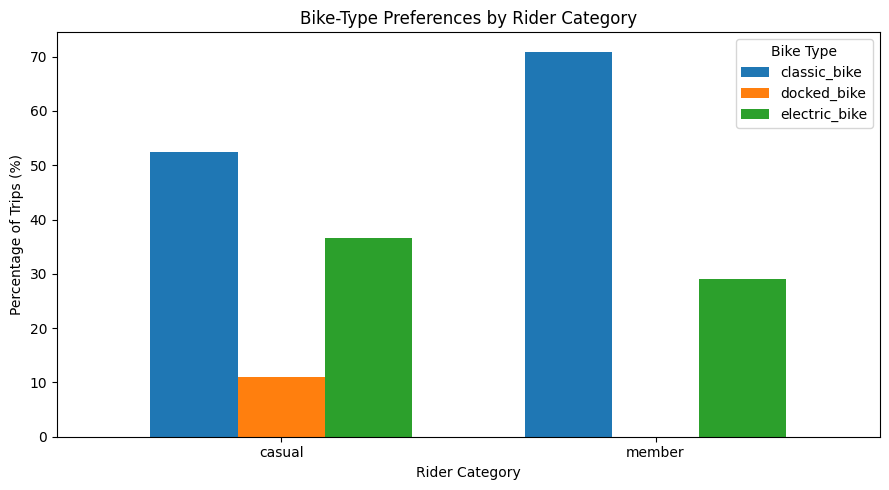

In [26]:
ax = bike_percentages.plot(
    kind="bar",
    figsize=(9, 5),
    width=0.7
)

ax.set_title("Bike-Type Preferences by Rider Category")
ax.set_xlabel("Rider Category")
ax.set_ylabel("Percentage of Trips (%)")
ax.legend(title="Bike Type")
ax.tick_params(axis="x", rotation=0)

plt.tight_layout()
plt.show()

### How does usage vary by day of the week?
Count trips by day and rider category

In [27]:
# Define weekday order
weekday_order = [
    "Monday", "Tuesday", "Wednesday", "Thursday",
    "Friday", "Saturday", "Sunday"
]

# Count trips by weekday and rider category
weekday_counts = pd.crosstab(
    df["day_name"],
    df["member_casual"]
).reindex(weekday_order)

display(weekday_counts)

member_casual,casual,member
day_name,,
Monday,69890,135645
Tuesday,73414,150535
Wednesday,72584,154398
Thursday,65843,133687
Friday,90234,141841
Saturday,143961,144821
Sunday,121782,126259


Plot weekday usage

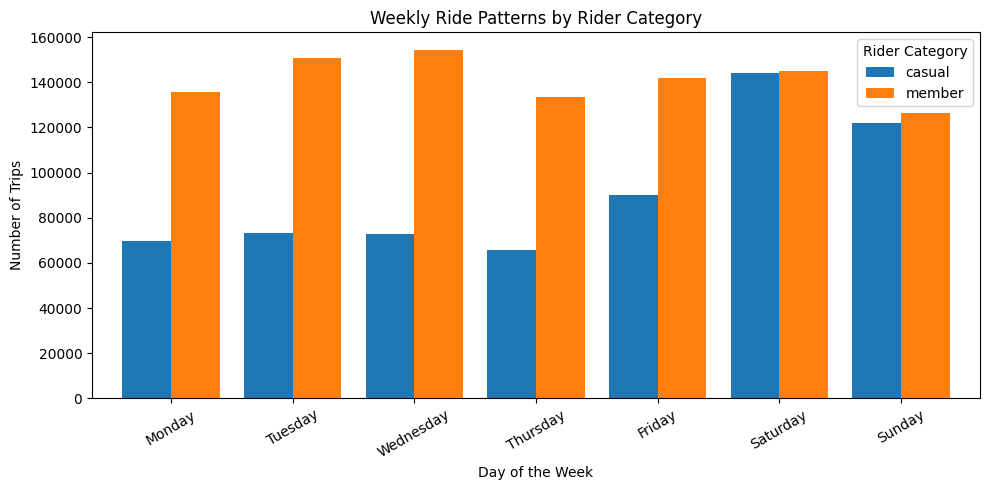

In [28]:
ax = weekday_counts.plot(
    kind="bar",
    figsize=(10, 5),
    width=0.8
)

ax.set_title("Weekly Ride Patterns by Rider Category")
ax.set_xlabel("Day of the Week")
ax.set_ylabel("Number of Trips")
ax.legend(title="Rider Category")
ax.tick_params(axis="x", rotation=30)

plt.tight_layout()
plt.show()

Compare the distribution fairly

member_casual,casual,member
day_name,,
Monday,10.96,13.74
Tuesday,11.51,15.25
Wednesday,11.38,15.64
Thursday,10.32,13.54
Friday,14.15,14.37
Saturday,22.57,14.67
Sunday,19.10,12.79


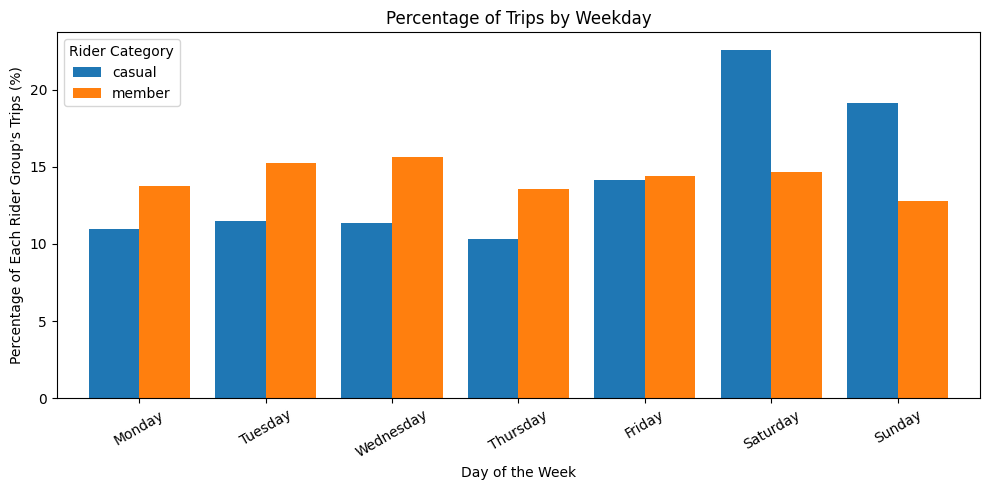

In [29]:
weekday_percentages = (
    pd.crosstab(
        df["day_name"],
        df["member_casual"],
        normalize="columns"
    ) * 100
).reindex(weekday_order)

display(weekday_percentages.round(2))

ax = weekday_percentages.plot(
    kind="bar",
    figsize=(10, 5),
    width=0.8
)

ax.set_title("Percentage of Trips by Weekday")
ax.set_xlabel("Day of the Week")
ax.set_ylabel("Percentage of Each Rider Group's Trips (%)")
ax.legend(title="Rider Category")
ax.tick_params(axis="x", rotation=30)

plt.tight_layout()
plt.show()